<a href="https://colab.research.google.com/github/sannidhi-works/Program-2-Classical-and-Distributed-Word-Representation-Techniques/blob/main/Program2_Word_Representations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Program 2: Classical and Distributed Word Representation Techniques
**Bag-of-Words vs TF-IDF vs Word2Vec / GloVe on AG News**

**Aim:** build BoW and TF-IDF representations, compare them with Word2Vec / GloVe embeddings for similarity and downstream classification, then push the best pipeline further with stratified K-fold, out-of-fold (OOF) stacking and bagging.

**Problem:** a digital news desk wants related stories grouped and incoming articles routed to *World, Sports, Business* or *Sci/Tech*.

> **Before you run anything:** Runtime → Change runtime type → **T4 GPU** → Save. The GPU is used by the PyTorch MLP head in the stacking section (gensim and scikit-learn run on CPU).

## Step 0: Environment check and installs
Quick look at the GPU, then install the two libraries Colab doesn't ship by default. If pip complains about a NumPy binary mismatch afterwards, do *Runtime → Restart session* and run from the top once more.

In [ ]:
!nvidia-smi
!pip -q install -U datasets gensim

Fri Nov  6 15:51:56 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   51C    P8             14W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## Step 1: Imports, seeds and global settings
Everything lives in one place so the experiment is reproducible. The two flags at the bottom are worth knowing about:
- `W2V_EXTRA_DOCS` lets Word2Vec read extra **unlabelled** training-split articles (never the test set, never labels). Set it to `0` if you want to follow the lab strictly with only the 8,000 training records.
- `USE_GLOVE` also downloads small pretrained GloVe vectors for comparison.

In [ ]:
import os, re, html, time, random, warnings
from collections import Counter
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F

from datasets import load_dataset
import nltk
from gensim.models import Word2Vec

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import BaggingClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
PALETTE = ["#4c78a8", "#f58518", "#54a24b", "#e45756"]

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Torch device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "no GPU found, turn on the T4 runtime")

N_TRAIN, N_TEST = 8000, 2000       # lab subset sizes
W2V_EXTRA_DOCS = 40000             # extra *unlabelled* training articles for Word2Vec (0 = strict lab mode)
USE_GLOVE = True                   # compare against pretrained GloVe-100 as well
N_SPLITS = 5
LABELS = ["World", "Sports", "Business", "Sci/Tech"]

Torch device: cuda | Tesla T4


## Step 2: Load AG News and take the stratified lab subset
The dataset comes straight from Hugging Face, no Kaggle account needed. I draw 8,000 training and 2,000 test records with stratification so each of the four classes keeps its share. Whatever training rows I don't use become the pool of unlabelled text for Word2Vec.

In [ ]:
ds = load_dataset("fancyzhx/ag_news")
train_full = ds["train"].to_pandas()
test_full = ds["test"].to_pandas()
print("Full train:", train_full.shape, "| full test:", test_full.shape)

train_df, _ = train_test_split(train_full, train_size=N_TRAIN, stratify=train_full["label"], random_state=SEED)
test_df, _ = train_test_split(test_full, train_size=N_TEST, stratify=test_full["label"], random_state=SEED)

# unlabelled pool for Word2Vec: rows of the training split that are NOT in our 8k sample
pool_df = train_full.drop(train_df.index)
pool_df = pool_df.sample(min(W2V_EXTRA_DOCS, len(pool_df)), random_state=SEED) if W2V_EXTRA_DOCS > 0 else pool_df.iloc[:0]

train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)
pool_df = pool_df.reset_index(drop=True)

for d in (train_df, test_df):
    d["label_name"] = d["label"].map(dict(enumerate(LABELS)))

y_tr, y_te = train_df["label"].values, test_df["label"].values
print(f"Train: {len(train_df)} | Test: {len(test_df)} | Unlabelled pool for Word2Vec: {len(pool_df)}")
train_df.head()

Full train: (120000, 2) | full test: (7600, 2)
Train: 8000 | Test: 2000 | Unlabelled pool for Word2Vec: 40000


,text,label,label_name
0,Call for bandit death inquiry A leading human ...,0,World
1,Air crash hits NASCAR team A plane owned by le...,1,Sports
2,Semiconductor Sales Booming in 2004 Worldwide ...,3,Sci/Tech
3,Delta pilots OK 32.5 pay cut ATLANTA -- Delta ...,2,Business
4,"Japan, Philippines Reach Free Trade Deal Japan...",0,World


## Step 3: Exploratory data analysis
Before any modelling I want to know three things: are the classes balanced, how long are the articles, and which words characterise each topic. The answers decide how I preprocess and which metric I trust (macro F1 is still the safest choice).

Missing values: 0
Duplicate articles: 0
Mean / median words per article: 38.0 / 37

Class share (train):
 label_name
World       0.25
Sports      0.25
Sci/Tech    0.25
Business    0.25

Class share (test):
 label_name
Sci/Tech    0.25
Business    0.25
Sports      0.25
World       0.25


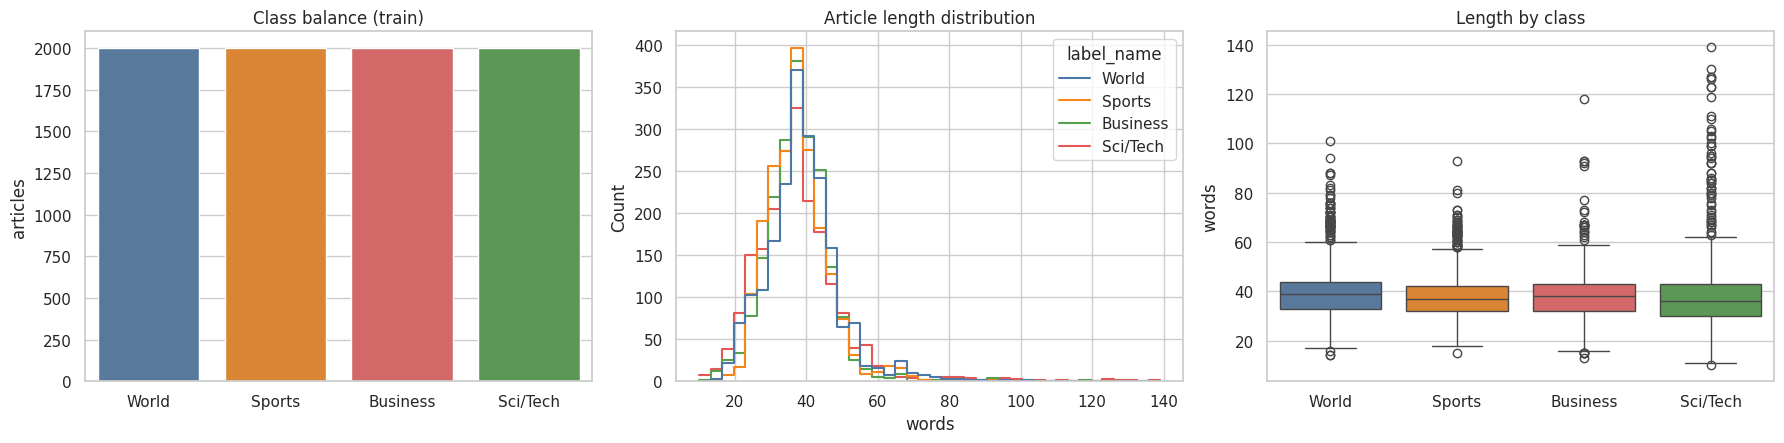

In [ ]:
train_df["n_words"] = train_df["text"].str.split().str.len()

print("Missing values:", int(train_df["text"].isna().sum()))
print("Duplicate articles:", int(train_df["text"].duplicated().sum()))
print("Mean / median words per article:", round(train_df["n_words"].mean(), 1), "/", int(train_df["n_words"].median()))
print("\nClass share (train):\n", train_df["label_name"].value_counts(normalize=True).round(3).to_string())
print("\nClass share (test):\n", test_df["label_name"].value_counts(normalize=True).round(3).to_string())

fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
sns.countplot(data=train_df, x="label_name", hue="label_name", order=LABELS, palette=PALETTE, legend=False, ax=axes[0])
axes[0].set_title("Class balance (train)"); axes[0].set_xlabel(""); axes[0].set_ylabel("articles")

sns.histplot(data=train_df, x="n_words", hue="label_name", hue_order=LABELS, palette=PALETTE,
             bins=40, element="step", fill=False, ax=axes[1])
axes[1].set_title("Article length distribution"); axes[1].set_xlabel("words")

sns.boxplot(data=train_df, x="label_name", y="n_words", hue="label_name", order=LABELS, palette=PALETTE, legend=False, ax=axes[2])
axes[2].set_title("Length by class"); axes[2].set_xlabel(""); axes[2].set_ylabel("words")
plt.tight_layout(); plt.show()

## Step 4: Preprocessing pipeline (reused from Program 1)
AG News text is a bit messy (HTML entities like `&lt;`, stray backslashes, URLs, agency tags). The pipeline: unescape HTML, strip tags/URLs/backslashes, lowercase, keep letters only, tokenise, drop stop-words and very short tokens, lemmatise.

I keep two versions of every article: `clean` (tokens joined, for word-level models) and `light` (just cleaned, no lemmatising or stop-word removal, for character n-grams later).

In [ ]:
nltk.download("stopwords", quiet=True); nltk.download("wordnet", quiet=True); nltk.download("omw-1.4", quiet=True)
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

STOP = set(stopwords.words("english"))
_lemmatizer = WordNetLemmatizer()

@lru_cache(maxsize=None)
def lemma(word):
    return _lemmatizer.lemmatize(word)

def light_clean(text):
    text = html.unescape(text)
    text = text.replace("\\", " ")
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text.lower())
    return re.sub(r"\s+", " ", text).strip()

def tokenize(clean_text):
    return [lemma(w) for w in clean_text.split() if len(w) > 2 and w not in STOP]

t0 = time.time()
for d in (train_df, test_df):
    d["light"] = d["text"].map(light_clean)
    d["tokens"] = d["light"].map(tokenize)
    d["clean"] = d["tokens"].map(" ".join)
pool_tokens = [tokenize(light_clean(t)) for t in pool_df["text"]]
print(f"Preprocessing done in {time.time() - t0:.1f}s")

i = 3
print("\nRAW  :", train_df["text"][i])
print("CLEAN:", train_df["clean"][i])

Preprocessing done in 11.9s

RAW  : Delta pilots OK 32.5 pay cut ATLANTA -- Delta Air Lines pilots handed the struggling airline a huge victory yesterday in its effort to avoid bankruptcy, agreeing to slash their salaries by more than \$1 billion annually and forgo pay raises through 2009.
CLEAN: delta pilot pay cut atlanta delta air line pilot handed struggling airline huge victory yesterday effort avoid bankruptcy agreeing slash salary billion annually forgo pay raise


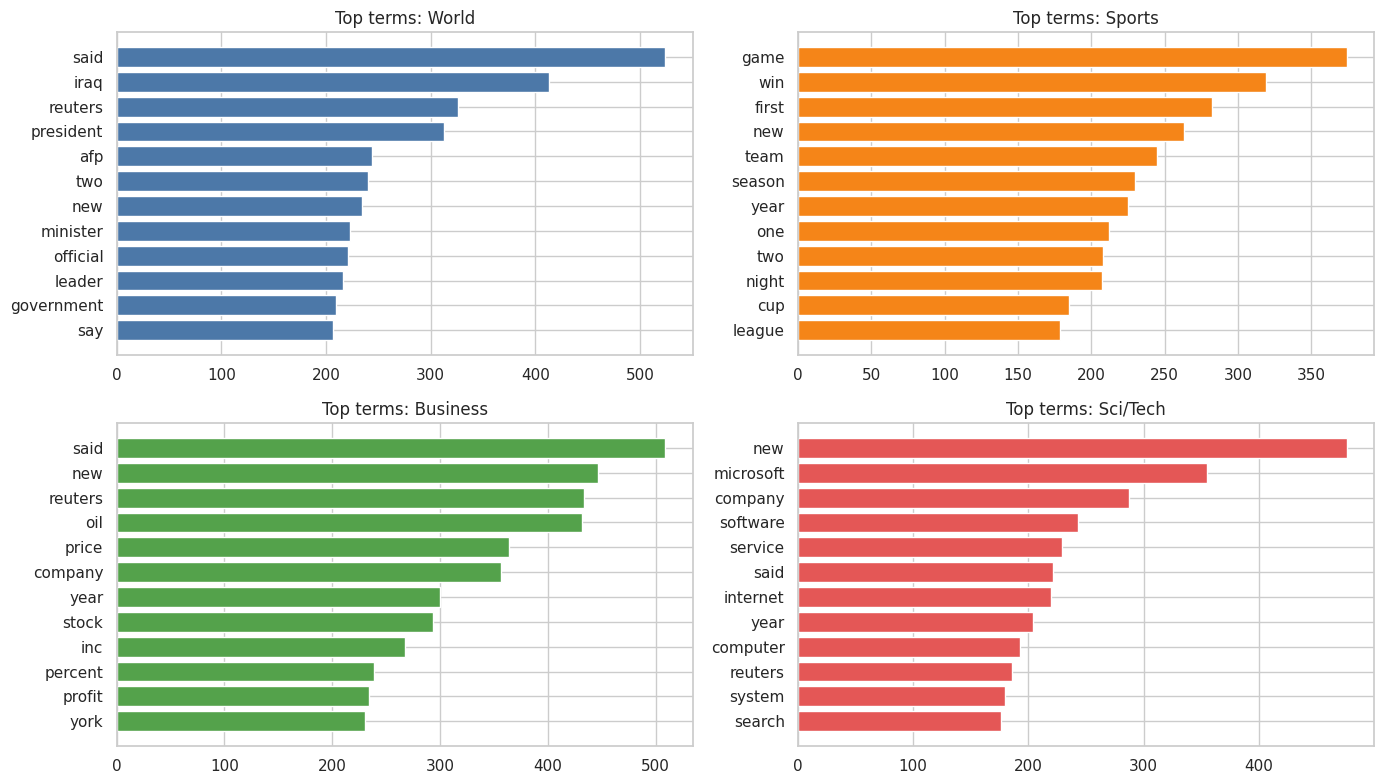

In [ ]:
# Which words dominate each topic after cleaning?
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, (lab, colour) in zip(axes.ravel(), zip(LABELS, PALETTE)):
    counts = Counter(w for toks in train_df.loc[train_df["label_name"] == lab, "tokens"] for w in toks)
    words, freqs = zip(*counts.most_common(12))
    ax.barh(words[::-1], freqs[::-1], color=colour)
    ax.set_title(f"Top terms: {lab}")
plt.tight_layout(); plt.show()

## Step 5: Bag-of-Words features
`CountVectorizer` is fitted on the **training text only**, then applied to the test set, so nothing from the test data leaks into the vocabulary. I ignore terms that appear in fewer than 2 documents, which keeps the matrix manageable.

In [ ]:
bow = CountVectorizer(min_df=2)
Xtr_bow = bow.fit_transform(train_df["clean"])
Xte_bow = bow.transform(test_df["clean"])

vocab_bow = np.array(bow.get_feature_names_out())
term_freq = np.asarray(Xtr_bow.sum(axis=0)).ravel()
density = Xtr_bow.nnz / (Xtr_bow.shape[0] * Xtr_bow.shape[1])

print("BoW vocabulary size :", len(vocab_bow))
print("Train matrix shape  :", Xtr_bow.shape, "| test:", Xte_bow.shape)
print(f"Non-zero density    : {density:.4%}  (sparsity {1 - density:.4%})")

top = term_freq.argsort()[::-1][:15]
print("\nMost frequent terms:", ", ".join(f"{vocab_bow[j]} ({term_freq[j]})" for j in top))

BoW vocabulary size : 10367
Train matrix shape  : (8000, 10367) | test: (2000, 10367)
Non-zero density    : 0.1950%  (sparsity 99.8050%)

Most frequent terms: new (1420), said (1355), reuters (1050), year (917), company (667), two (659), first (658), quot (586), one (570), world (546), monday (536), wednesday (535), oil (532), game (526), say (504)


## Step 6: TF-IDF features (unigrams + bigrams)
Same idea, but each count is scaled by how rare the term is across the corpus. I use unigrams plus bigrams (so "wall street" or "world cup" become features), `sublinear_tf` to damp very repeated words, and the default L2 normalisation.

In [ ]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
Xtr_tfidf = tfidf.fit_transform(train_df["clean"])
Xte_tfidf = tfidf.transform(test_df["clean"])
vocab_tf = np.array(tfidf.get_feature_names_out())

print("TF-IDF vocabulary size:", len(vocab_tf), "| shape:", Xtr_tfidf.shape)
print(f"Density: {Xtr_tfidf.nnz / (Xtr_tfidf.shape[0] * Xtr_tfidf.shape[1]):.4%}")

# highest-weight terms for one representative article per class
for k, lab in enumerate(LABELS):
    row = Xtr_tfidf[train_df.index[train_df["label"] == k][0]]
    best = row.toarray().ravel().argsort()[::-1][:6]
    print(f"{lab:9s}->", ", ".join(f"{vocab_tf[j]} ({row[0, j]:.2f})" for j in best))

# lowest-idf terms = the words TF-IDF refuses to get excited about
idf_order = tfidf.idf_.argsort()[:12]
print("\nLowest-IDF (most common) terms:", ", ".join(vocab_tf[idf_order]))

TF-IDF vocabulary size: 26857 | shape: (8000, 26857)
Density: 0.1015%
World    -> bandit (0.53), police kill (0.29), right group (0.28), notorious (0.27), inquiry (0.24), human right (0.24)
Sports   -> nascar (0.30), stock car (0.23), motorsports crashed (0.23), nascar race (0.23), team plane (0.23), nascar team (0.23)
Business -> pilot (0.27), delta (0.26), pay (0.21), victory yesterday (0.21), bankruptcy agreeing (0.21), effort avoid (0.21)
Sci/Tech -> semiconductor sale (0.45), semiconductor (0.33), reach billion (0.26), according latest (0.25), billion percent (0.25), worldwide semiconductor (0.25)

Lowest-IDF (most common) terms: said, new, year, reuters, company, two, first, wednesday, monday, one, thursday, tuesday


## Step 7: Distributed embeddings (Word2Vec, plus optional GloVe)
I train both Word2Vec flavours, **CBOW** (`sg=0`) and **Skip-gram** (`sg=1`), on the tokenised text, then pick the better one using 3-fold cross-validation on the *training* labels only (so the test set stays untouched). A document vector is the average of its token vectors.

In [ ]:
w2v_sentences = list(train_df["tokens"]) + pool_tokens
print("Sentences used to train Word2Vec:", len(w2v_sentences))

def train_w2v(sg):
    return Word2Vec(w2v_sentences, vector_size=200, window=5, min_count=3, sg=sg,
                    negative=10, epochs=20, workers=os.cpu_count() or 2, seed=SEED)

def doc_vector(tokens, wv, idf=None, default=1.0):
    vecs, weights = [], []
    for t in tokens:
        if t in wv.key_to_index:
            vecs.append(wv[t])
            weights.append(idf.get(t, default) if idf else 1.0)
    if not vecs:
        return np.zeros(wv.vector_size, dtype=np.float32)
    return np.average(vecs, axis=0, weights=weights)

def embed_corpus(token_lists, wv, idf=None, default=1.0):
    return np.vstack([doc_vector(t, wv, idf, default) for t in token_lists]).astype(np.float32)

w2v_models, w2v_cv = {}, {}
cv3 = StratifiedKFold(3, shuffle=True, random_state=SEED)
for sg, name in [(0, "CBOW"), (1, "Skip-gram")]:
    t0 = time.time()
    w2v_models[name] = train_w2v(sg)
    E = embed_corpus(train_df["tokens"], w2v_models[name].wv)
    cv_pipe = Pipeline([("sc", StandardScaler()), ("lr", LogisticRegression(max_iter=2000))])
    w2v_cv[name] = cross_val_score(cv_pipe, E, y_tr, cv=cv3, scoring="f1_macro").mean()
    print(f"{name:10s} vocab={len(w2v_models[name].wv):6d}  train time={time.time() - t0:5.1f}s  CV macro-F1={w2v_cv[name]:.4f}")

best_w2v = max(w2v_cv, key=w2v_cv.get)
wv = w2v_models[best_w2v].wv
print("\nUsing:", best_w2v)

Sentences used to train Word2Vec: 48000
CBOW       vocab= 20373  train time= 85.7s  CV macro-F1=0.8634
Skip-gram  vocab= 20373  train time=286.1s  CV macro-F1=0.8730

Using: Skip-gram


In [ ]:
# Document vectors: plain average and IDF-weighted average (rare words count more)
n_docs = len(train_df)
doc_freq = Counter(w for toks in train_df["tokens"] for w in set(toks))
idf_map = {w: np.log((1 + n_docs) / (1 + c)) + 1 for w, c in doc_freq.items()}
idf_default = np.log(1 + n_docs) + 1

E_tr = embed_corpus(train_df["tokens"], wv);                         E_te = embed_corpus(test_df["tokens"], wv)
Eidf_tr = embed_corpus(train_df["tokens"], wv, idf_map, idf_default); Eidf_te = embed_corpus(test_df["tokens"], wv, idf_map, idf_default)
print("Word2Vec doc matrices:", E_tr.shape, E_te.shape)

# Optional pretrained GloVe
glove = None
if USE_GLOVE:
    try:
        import gensim.downloader as api
        glove = api.load("glove-wiki-gigaword-100")
        G_tr = embed_corpus(train_df["tokens"], glove); G_te = embed_corpus(test_df["tokens"], glove)
        Gidf_tr = embed_corpus(train_df["tokens"], glove, idf_map, idf_default); Gidf_te = embed_corpus(test_df["tokens"], glove, idf_map, idf_default)
        print("GloVe loaded:", len(glove.key_to_index), "words | doc matrices:", G_tr.shape)
    except Exception as e:
        print("GloVe download failed, continuing without it:", e)
        glove = None

## Step 8: Out-of-vocabulary behaviour
Any test token the model never saw during fitting is invisible to it. Here I measure how much of the test text each representation actually "sees".

In [ ]:
test_tokens_flat = [t for toks in test_df["tokens"] for t in toks]

def oov_rate(vocab):
    return np.mean([t not in vocab for t in test_tokens_flat])

oov_table = {"BoW / TF-IDF unigram vocab": oov_rate(set(vocab_bow)),
             f"Word2Vec ({best_w2v})": oov_rate(wv.key_to_index)}
if glove is not None:
    oov_table["GloVe-100"] = oov_rate(glove.key_to_index)

oov_df = pd.DataFrame({"OOV token rate on test": oov_table}).style.format("{:.2%}")
display(oov_df)
print("Test articles with zero in-vocabulary Word2Vec tokens:",
      int((np.abs(E_te).sum(axis=1) == 0).sum()))

## Step 9: Similarity analysis
### 9a. Word-level similarity (Word2Vec)
Cosine similarity for chosen word pairs and the nearest neighbours of a few topic words. If the embedding space is good, related words should score high and unrelated ones low.

In [12]:
pairs = [("oil", "price"), ("game", "team"), ("president", "minister"), ("computer", "software"),
         ("stock", "market"), ("game", "oil"), ("election", "software")]
rows = []
for a, b in pairs:
    if a in wv.key_to_index and b in wv.key_to_index:
        rows.append({"word A": a, "word B": b, "cosine": round(float(wv.similarity(a, b)), 3)})
display(pd.DataFrame(rows))

for w in ["oil", "game", "president", "computer", "market"]:
    if w in wv.key_to_index:
        print(f"{w:10s}->", ", ".join(f"{n} ({s:.2f})" for n, s in wv.most_similar(w, topn=6)))

,word A,word B,cosine
0,oil,price,0.604
1,game,team,0.312
2,president,minister,0.398
3,computer,software,0.458
4,stock,market,0.382
5,game,oil,0.123
6,election,software,0.141


oil       -> crude (0.77), nymex (0.64), petroleum (0.63), price (0.60), soothed (0.60), barrel (0.60)
game      -> rabid (0.51), purist (0.51), deserving (0.50), guidugli (0.50), criminally (0.50), scrimmage (0.50)
president -> bush (0.62), staunchly (0.62), inacio (0.58), joyce (0.57), hosni (0.56), luiz (0.55)
computer  -> pc (0.55), machine (0.54), networked (0.53), surreptitiously (0.53), finjan (0.52), hacker (0.51)
market    -> jittery (0.49), plmo (0.48), loosens (0.48), abounds (0.48), fluctuation (0.47), foothold (0.47)
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


### 9b. Document-level similarity across representations
For a few test articles I retrieve the three most similar *training* articles under each representation and check whether they share the query's topic.

In [13]:
sim_reps = {"BoW": (Xtr_bow, Xte_bow),
            "TF-IDF": (Xtr_tfidf, Xte_tfidf),
            "Word2Vec avg": (E_tr, E_te),
            "Word2Vec idf-avg": (Eidf_tr, Eidf_te)}
if glove is not None:
    sim_reps["GloVe avg"] = (G_tr, G_te)

def show_neighbours(q, k=3):
    print("=" * 100)
    print(f"QUERY [{LABELS[y_te[q]]}]: {test_df['text'][q][:170]}...")
    for name, (A_tr, A_te) in sim_reps.items():
        sims = cosine_similarity(A_te[[q]], A_tr).ravel()
        print(f"  {name}")
        for j in sims.argsort()[::-1][:k]:
            print(f"     {sims[j]:.3f} [{LABELS[y_tr[j]]:8s}] {train_df['text'][j][:90]}...")

for k in range(4):
    show_neighbours(int(np.where(y_te == k)[0][0]))

QUERY [World]: Landmine kills Darfur aid workers Two aid workers are killed in Sudan's Darfur region after their vehicle hit a landmine....
  BoW
     0.412 [World   ] At Least 17 Killed in Darfur Fighting (AP) AP - Fighting near a village in Sudan's crisis-...
     0.334 [World   ] Call for more Darfur peacekeepers More peacekeepers are needed in Sudan's Darfur region to...
     0.331 [World   ] Special UN envoy urges Sudan to accept more foreign aid (AFP) AFP - UN chief Kofi Annan's ...
  TF-IDF
     0.393 [World   ] Call for more Darfur peacekeepers More peacekeepers are needed in Sudan's Darfur region to...
     0.317 [World   ] At Least 17 Killed in Darfur Fighting (AP) AP - Fighting near a village in Sudan's crisis-...
     0.314 [World   ] Insecurity Cuts Off 360,000 of Darfur's Needy-WFP (Reuters) Reuters - About 360,000 needy ...
  Word2Vec avg
     0.902 [World   ] At Least 17 Killed in Darfur Fighting (AP) AP - Fighting near a village in Sudan's crisis-...
     0.862 [World 

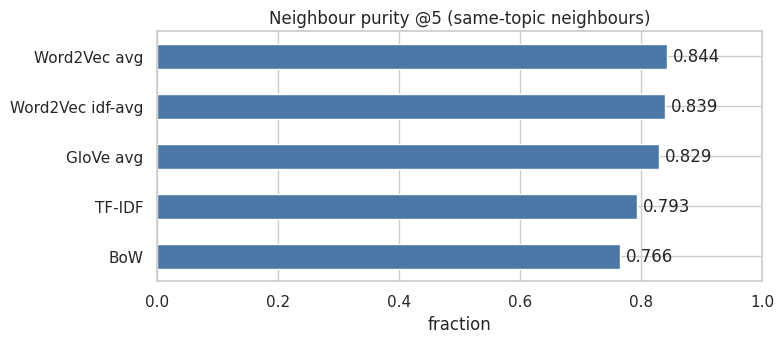

In [14]:
# A number instead of eyeballing: how often are the 5 nearest training articles from the same topic?
def knn_purity(A_tr, A_te, k=5):
    sims = cosine_similarity(A_te, A_tr)
    top = np.argpartition(-sims, k, axis=1)[:, :k]
    return (y_tr[top] == y_te[:, None]).mean()

purity = pd.Series({n: knn_purity(a, b) for n, (a, b) in sim_reps.items()}).sort_values()
ax = purity.plot.barh(color="#4c78a8", figsize=(8, 3.6), xlim=(0, 1))
ax.set_title("Neighbour purity @5 (same-topic neighbours)"); ax.set_xlabel("fraction")
for i, v in enumerate(purity.values): ax.text(v + 0.01, i, f"{v:.3f}", va="center")
plt.tight_layout(); plt.show()

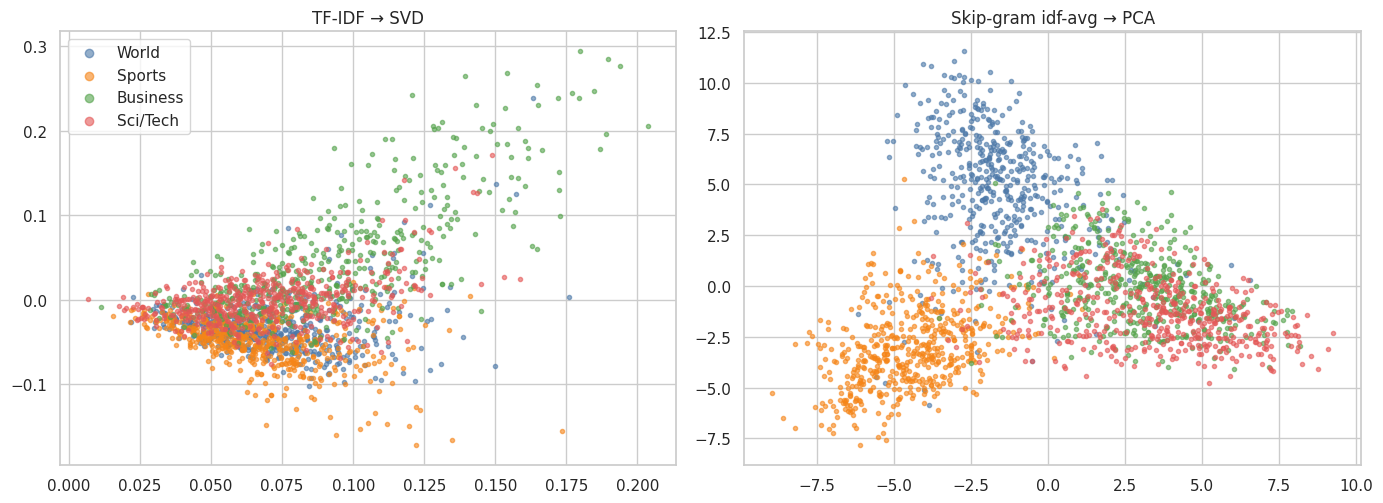

In [15]:
# 2-D picture of the two worlds: sparse TF-IDF (SVD) vs dense embeddings (PCA)
rng = np.random.RandomState(SEED)
sel = rng.choice(len(train_df), 2000, replace=False)
p_tfidf = TruncatedSVD(2, random_state=SEED).fit_transform(Xtr_tfidf[sel])
p_w2v = PCA(2, random_state=SEED).fit_transform(StandardScaler().fit_transform(Eidf_tr[sel]))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for ax, pts, title in zip(axes, (p_tfidf, p_w2v), ("TF-IDF → SVD", f"{best_w2v} idf-avg → PCA")):
    for k, lab in enumerate(LABELS):
        m = y_tr[sel] == k
        ax.scatter(pts[m, 0], pts[m, 1], s=9, alpha=0.6, label=lab, color=PALETTE[k])
    ax.set_title(title)
axes[0].legend(markerscale=2)
plt.tight_layout(); plt.show()

## Step 10: Fair comparison, same classifier on every representation
Now the head-to-head the lab asks for. Every representation gets the identical classifier (logistic regression, same settings). Dense embeddings are standardised first because averaged vectors have very different scales per dimension. I record accuracy, macro precision/recall/F1, dimensionality, sparsity and fit time.

,Accuracy,Macro-P,Macro-R,Macro-F1,Dims,Sparsity,Fit time (s)
Representation,,,,,,,
BoW,0.8630,0.8624,0.8630,0.8626,10367,99.81%,1.18
TF-IDF (1-2 gram),0.8815,0.8811,0.8815,0.8811,26857,99.90%,1.46
Skip-gram avg,0.8790,0.8790,0.8790,0.8789,200,0.00%,0.94
Skip-gram idf-avg,0.8765,0.8768,0.8765,0.8765,200,0.00%,0.57
GloVe-100 avg,0.8720,0.8714,0.8720,0.8715,100,0.00%,0.56
GloVe-100 idf-avg,0.8710,0.8708,0.8710,0.8708,100,0.00%,0.56


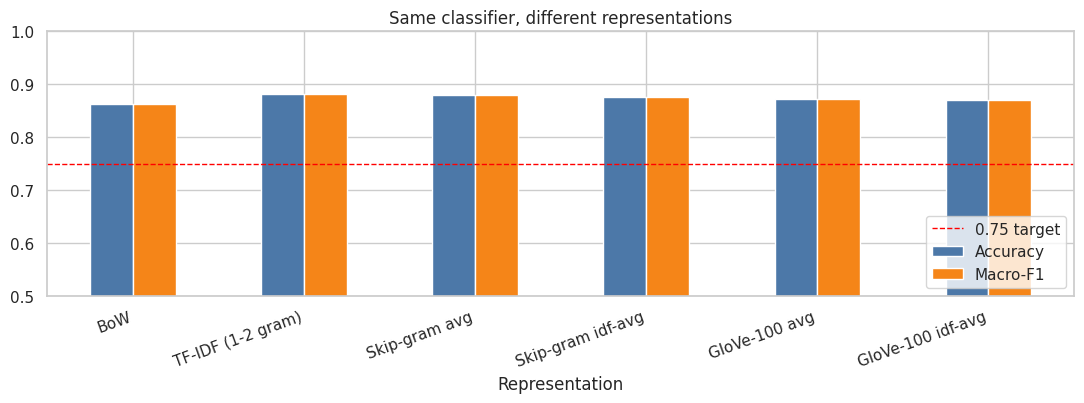

In [16]:
def score(y_true, y_pred):
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Macro-P": precision_score(y_true, y_pred, average="macro"),
            "Macro-R": recall_score(y_true, y_pred, average="macro"),
            "Macro-F1": f1_score(y_true, y_pred, average="macro")}

reps = {"BoW": (Xtr_bow, Xte_bow, False),
        "TF-IDF (1-2 gram)": (Xtr_tfidf, Xte_tfidf, False),
        f"{best_w2v} avg": (E_tr, E_te, True),
        f"{best_w2v} idf-avg": (Eidf_tr, Eidf_te, True)}
if glove is not None:
    reps["GloVe-100 avg"] = (G_tr, G_te, True)
    reps["GloVe-100 idf-avg"] = (Gidf_tr, Gidf_te, True)

rows, base_preds = [], {}
for name, (A_tr, A_te, dense) in reps.items():
    steps = ([("sc", StandardScaler())] if dense else []) + [("lr", LogisticRegression(C=1.0, max_iter=3000))]
    clf = Pipeline(steps)
    t0 = time.time(); clf.fit(A_tr, y_tr); fit_s = time.time() - t0
    pred = clf.predict(A_te); base_preds[name] = pred
    nnz = A_tr.nnz if hasattr(A_tr, "nnz") else np.count_nonzero(A_tr)
    rows.append({"Representation": name, **score(y_te, pred), "Dims": A_tr.shape[1],
                 "Sparsity": 1 - nnz / (A_tr.shape[0] * A_tr.shape[1]), "Fit time (s)": fit_s})

baseline_df = pd.DataFrame(rows).set_index("Representation")
display(baseline_df.style.format({"Accuracy": "{:.4f}", "Macro-P": "{:.4f}", "Macro-R": "{:.4f}", "Macro-F1": "{:.4f}",
                                  "Sparsity": "{:.2%}", "Fit time (s)": "{:.2f}"}).background_gradient(subset=["Macro-F1"], cmap="Greens"))

ax = baseline_df[["Accuracy", "Macro-F1"]].plot.bar(figsize=(11, 4.2), color=["#4c78a8", "#f58518"], ylim=(0.5, 1))
ax.axhline(0.75, color="red", ls="--", lw=1, label="0.75 target")
ax.set_title("Same classifier, different representations"); ax.legend(loc="lower right"); plt.xticks(rotation=20, ha="right")
plt.tight_layout(); plt.show()

## Step 11: Optimised approach. Stratified K-Fold, OOF predictions, bagging and stacking
The baselines are decent, but a single model on a single representation leaves accuracy on the table. The plan:

1. Build several **diverse base models**: word TF-IDF (logistic regression, calibrated linear SVM, Complement NB), **character n-gram** TF-IDF, a **bagged** logistic regression on embeddings, and a small **GPU-trained MLP** on idf-weighted embeddings (plus GloVe if available).
2. Produce **out-of-fold** probabilities with `StratifiedKFold`: every training row is predicted by a model that never saw it, so the meta-learner trains on honest predictions.
3. Average each model's fold predictions for the test set, then train a **logistic-regression meta-learner** on the stacked OOF probabilities.

Text vectorisers sit *inside* the pipelines, so vocabularies and IDF are re-fitted within each fold with no leakage. (Word2Vec itself is trained once; it is unsupervised and never sees labels or test text.)

In [17]:
class TorchMLP:
    """Small sklearn-style MLP that trains on the GPU (T4) when available."""
    def __init__(self, hidden=256, epochs=60, lr=1e-3, wd=1e-3, dropout=0.3, batch=256, seed=SEED):
        self.hidden, self.epochs, self.lr, self.wd = hidden, epochs, lr, wd
        self.dropout, self.batch, self.seed = dropout, batch, seed

    def fit(self, X, y):
        torch.manual_seed(self.seed)
        self.scaler = StandardScaler().fit(X)
        Xt = torch.tensor(self.scaler.transform(X), dtype=torch.float32, device=device)
        yt = torch.tensor(y, dtype=torch.long, device=device)
        h = self.hidden
        self.net = nn.Sequential(nn.Linear(Xt.shape[1], h), nn.ReLU(), nn.Dropout(self.dropout),
                                 nn.Linear(h, h // 2), nn.ReLU(), nn.Dropout(self.dropout),
                                 nn.Linear(h // 2, len(LABELS))).to(device)
        opt = torch.optim.AdamW(self.net.parameters(), lr=self.lr, weight_decay=self.wd)
        n = len(Xt)
        for _ in range(self.epochs):
            self.net.train()
            perm = torch.randperm(n, device=device)
            for i in range(0, n, self.batch):
                idx = perm[i:i + self.batch]
                opt.zero_grad()
                loss = F.cross_entropy(self.net(Xt[idx]), yt[idx], label_smoothing=0.05)
                loss.backward(); opt.step()
        return self

    def predict_proba(self, X):
        self.net.eval()
        with torch.no_grad():
            Xt = torch.tensor(self.scaler.transform(X), dtype=torch.float32, device=device)
            return F.softmax(self.net(Xt), dim=1).cpu().numpy()

    def predict(self, X):
        return self.predict_proba(X).argmax(1)


def run_oof(name, factory, X_train, y, X_test, skf):
    """Out-of-fold probabilities for the train set + fold-averaged probabilities for the test set."""
    oof = np.zeros((len(y), len(LABELS)))
    test_proba = np.zeros((len(X_test), len(LABELS)))
    t0 = time.time()
    for tr_idx, va_idx in skf.split(np.zeros(len(y)), y):
        model = factory().fit(X_train[tr_idx], y[tr_idx])
        oof[va_idx] = model.predict_proba(X_train[va_idx])
        test_proba += model.predict_proba(X_test) / skf.n_splits
    secs = time.time() - t0
    print(f"{name:14s} OOF macro-F1={f1_score(y, oof.argmax(1), average='macro'):.4f} | "
          f"test macro-F1={f1_score(y_te, test_proba.argmax(1), average='macro'):.4f} | {secs:5.1f}s")
    return oof, test_proba, secs

In [18]:
txt_tr, txt_te = train_df["clean"].values, test_df["clean"].values
light_tr, light_te = train_df["light"].values, test_df["light"].values

def make_bagged_lr():
    return Pipeline([("sc", StandardScaler()),
                     ("bag", BaggingClassifier(estimator=LogisticRegression(C=0.5, max_iter=2000), n_estimators=15,
                                               max_samples=0.8, max_features=0.8, bootstrap=True,
                                               n_jobs=-1, random_state=SEED))])

base_models = {
    "tfidf_lr":  (lambda: Pipeline([("v", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
                                    ("m", LogisticRegression(C=20, max_iter=3000))]), txt_tr, txt_te),
    "tfidf_svm": (lambda: Pipeline([("v", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
                                    ("m", CalibratedClassifierCV(LinearSVC(C=0.6), cv=3))]), txt_tr, txt_te),
    "tfidf_cnb": (lambda: Pipeline([("v", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
                                    ("m", ComplementNB(alpha=0.3))]), txt_tr, txt_te),
    "char_lr":   (lambda: Pipeline([("v", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=3,
                                                          sublinear_tf=True, max_features=120000)),
                                    ("m", LogisticRegression(C=20, max_iter=3000))]), light_tr, light_te),
    "w2v_bag":   (make_bagged_lr, Eidf_tr, Eidf_te),
    "w2v_mlp_gpu": (lambda: TorchMLP(), Eidf_tr, Eidf_te),
}
if glove is not None:
    base_models["glove_mlp_gpu"] = (lambda: TorchMLP(), Gidf_tr, Gidf_te)

skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
oof_store, test_store, time_store = {}, {}, {}
for name, (factory, Xa, Xb) in base_models.items():
    oof_store[name], test_store[name], time_store[name] = run_oof(name, factory, Xa, y_tr, Xb, skf)

tfidf_lr       OOF macro-F1=0.8861 | test macro-F1=0.8828 |  18.6s
tfidf_svm      OOF macro-F1=0.8906 | test macro-F1=0.8868 |   3.9s
tfidf_cnb      OOF macro-F1=0.8945 | test macro-F1=0.8853 |   2.5s
char_lr        OOF macro-F1=0.8766 | test macro-F1=0.8777 |  68.1s
w2v_bag        OOF macro-F1=0.8858 | test macro-F1=0.8744 |  15.4s
w2v_mlp_gpu    OOF macro-F1=0.8902 | test macro-F1=0.8863 |  22.0s
glove_mlp_gpu  OOF macro-F1=0.8845 | test macro-F1=0.8818 |  15.0s


## Step 12: Meta-learner (stacking) and blend
The meta-learner sees only the stacked OOF probabilities. I score it two ways: cross-validated on the training OOF matrix (honest estimate before touching the test set) and on the held-out test set. A plain probability average is included as a sanity-check blend.

In [ ]:
names = list(base_models)
meta_tr = np.hstack([oof_store[n] for n in names])
meta_te = np.hstack([test_store[n] for n in names])

meta = LogisticRegression(C=0.5, max_iter=3000)
meta_cv_pred = cross_val_predict(meta, meta_tr, y_tr, cv=StratifiedKFold(5, shuffle=True, random_state=SEED + 1))
print(f"Meta-learner CV macro-F1 (train OOF): {f1_score(y_tr, meta_cv_pred, average='macro'):.4f}")

t0 = time.time(); meta.fit(meta_tr, y_tr); meta_fit_s = time.time() - t0
stack_pred = meta.predict(meta_te)
blend_pred = np.mean([test_store[n] for n in names], axis=0).argmax(1)

print(f"Stacked  test macro-F1: {f1_score(y_te, stack_pred, average='macro'):.4f}")
print(f"Averaged test macro-F1: {f1_score(y_te, blend_pred, average='macro'):.4f}")

## Step 13: Model performance benchmark
Every model and both ensembles on the held-out 2,000-article test set, with total training time (including all CV folds).

In [ ]:
bench = []
for n in names:
    s = score(y_te, test_store[n].argmax(1))
    bench.append({"Model": n, **s, "OOF Macro-F1": f1_score(y_tr, oof_store[n].argmax(1), average="macro"), "Train time (s)": time_store[n]})
bench.append({"Model": "AVERAGE blend", **score(y_te, blend_pred), "OOF Macro-F1": np.nan, "Train time (s)": sum(time_store.values())})
bench.append({"Model": "STACKED (meta LR)", **score(y_te, stack_pred),
              "OOF Macro-F1": f1_score(y_tr, meta_cv_pred, average="macro"), "Train time (s)": sum(time_store.values()) + meta_fit_s})
bench_df = pd.DataFrame(bench).set_index("Model").sort_values("Macro-F1", ascending=False)

display(bench_df.style.format("{:.4f}", na_rep="-").background_gradient(subset=["Macro-F1"], cmap="Greens"))

fig, axes = plt.subplots(1, 2, figsize=(16, 4.6))
bench_df["Macro-F1"].sort_values().plot.barh(ax=axes[0], color="#54a24b", xlim=(0.5, 1))
axes[0].axvline(0.75, color="red", ls="--", lw=1); axes[0].set_title("Macro-F1 on the test set (red = 0.75 target)")
bench_df["Train time (s)"].sort_values().plot.barh(ax=axes[1], color="#4c78a8")
axes[1].set_title("Training time (s, includes all CV folds)")
plt.tight_layout(); plt.show()

best_row = bench_df.iloc[0]
print(f"Best: {bench_df.index[0]} with macro-F1 {best_row['Macro-F1']:.4f} -> target of 0.75 {'MET' if best_row['Macro-F1'] > 0.75 else 'NOT met'}")

## Step 14: Error analysis
Per-class scores and the confusion matrix for the stacked model, followed by a few articles it got wrong. Business and Sci/Tech usually blur together (a chip-maker's earnings call is both).

In [ ]:
print(classification_report(y_te, stack_pred, target_names=LABELS, digits=4))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay(confusion_matrix(y_te, stack_pred), display_labels=LABELS).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Stacked model: counts")
ConfusionMatrixDisplay(confusion_matrix(y_te, stack_pred, normalize="true"), display_labels=LABELS).plot(ax=axes[1], cmap="Blues", colorbar=False, values_format=".2f")
axes[1].set_title("Stacked model: row-normalised")
plt.tight_layout(); plt.show()

wrong = np.where(stack_pred != y_te)[0]
print(f"\n{len(wrong)} of {len(y_te)} test articles misclassified. A few of them:\n")
for j in wrong[:6]:
    print(f"true={LABELS[y_te[j]]:8s} pred={LABELS[stack_pred[j]]:8s} | {test_df['text'][j][:140]}...")

## Step 15: Observations to record
Everything the lab sheet asks to log, collected programmatically so the numbers always match the run.

In [24]:
print("DATASET AND SPLIT")
print(f"  AG News (fancyzhx/ag_news) | train={len(train_df)} test={len(test_df)} | stratified, seed={SEED}")
print(f"  Extra unlabelled docs for Word2Vec: {len(pool_df)}")
print("\nPREPROCESSING AND MODEL CONFIGURATION")
print("  Cleaning: html unescape, strip tags/urls/backslashes, lowercase, letters only, stop-words, len>2, WordNet lemmatiser")
print(f"  BoW: CountVectorizer(min_df=2) -> {len(vocab_bow)} features")
print(f"  TF-IDF: (1,2)-grams, min_df=2, sublinear_tf -> {len(vocab_tf)} features")
print(f"  Word2Vec: {best_w2v}, 200 dims, window 5, min_count 3, 20 epochs, vocab {len(wv)}")
print(f"  CV: StratifiedKFold({N_SPLITS}) with OOF stacking; base models: {', '.join(names)}")
print("\nEVALUATION")
display(baseline_df[["Accuracy", "Macro-F1", "Dims", "Sparsity", "Fit time (s)"]].round(4))
print(f"  Final stacked model: accuracy={accuracy_score(y_te, stack_pred):.4f}, macro-F1={f1_score(y_te, stack_pred, average='macro'):.4f}")
bench_df.to_csv("program2_benchmarks.csv"); baseline_df.to_csv("program2_baselines.csv")
print("  Saved program2_benchmarks.csv and program2_baselines.csv")

DATASET AND SPLIT
  AG News (fancyzhx/ag_news) | train=8000 test=2000 | stratified, seed=42
  Extra unlabelled docs for Word2Vec: 40000

PREPROCESSING AND MODEL CONFIGURATION
  Cleaning: html unescape, strip tags/urls/backslashes, lowercase, letters only, stop-words, len>2, WordNet lemmatiser
  BoW: CountVectorizer(min_df=2) -> 10367 features
  TF-IDF: (1,2)-grams, min_df=2, sublinear_tf -> 26857 features
  Word2Vec: Skip-gram, 200 dims, window 5, min_count 3, 20 epochs, vocab 20373
  CV: StratifiedKFold(5) with OOF stacking; base models: tfidf_lr, tfidf_svm, tfidf_cnb, char_lr, w2v_bag, w2v_mlp_gpu, glove_mlp_gpu

EVALUATION


,Accuracy,Macro-F1,Dims,Sparsity,Fit time (s)
Representation,,,,,
BoW,0.8630,0.8626,10367,0.9981,1.1834
TF-IDF (1-2 gram),0.8815,0.8811,26857,0.9990,1.4574
Skip-gram avg,0.8790,0.8789,200,0.0000,0.9378
Skip-gram idf-avg,0.8765,0.8765,200,0.0000,0.5711
GloVe-100 avg,0.8720,0.8715,100,0.0000,0.5623
GloVe-100 idf-avg,0.8710,0.8708,100,0.0000,0.5586


  Final stacked model: accuracy=0.8960, macro-F1=0.8960
  Saved program2_benchmarks.csv and program2_baselines.csv


### Errors, limitations, ethical considerations and proposed improvements
- **Errors:** Business vs Sci/Tech is the dominant confusion, since technology-company news genuinely belongs to both. Very short headlines carry few tokens, so averaged embeddings get noisy.
- **Limitations:** averaging discards word order and negation; Word2Vec trained on a modest news corpus has a small vocabulary and a real out-of-vocabulary rate; the dataset is English-only, 2004-era news from a limited set of sources, with only 4 coarse topics; results come from one 8k/2k split.
- **Ethical considerations:** news-routing models inherit the framing and source bias of their training data, and word embeddings can encode social stereotypes. Automated routing should keep a human editor in the loop, and misrouted stories (for example a political piece sent to Business) can change what readers see.
- **Proposed improvements:** fastText sub-word vectors for OOV words, SIF or Doc2Vec for document vectors, fine-tuning a small transformer on the T4, repeated stratified CV for tighter error bars, and probability calibration checks before using the model for automatic routing.

## Viva voce answers
<div style="border:2px solid #4c78a8; border-radius:10px; padding:16px 20px; background:rgba(76,120,168,0.08); line-height:1.55;">
<p><b>1. Why is TF-IDF less dominated by frequent words than BoW?</b><br>
BoW uses raw counts, so words that appear everywhere ("said", "new", "year") get the largest values and swamp the informative ones. TF-IDF multiplies the term frequency by the inverse document frequency, <i>idf(t) = log(N / df(t))</i> (smoothed in scikit-learn). A word found in most documents gets an idf close to its minimum, so its weight shrinks, while a word found in few documents ("playoff", "nasdaq") is boosted. Sublinear tf (<i>1 + log tf</i>) and L2 normalisation further stop long documents or heavily repeated words from dominating. The "Lowest-IDF terms" printed in Step 6 shows exactly which words get suppressed.</p>

<p><b>2. What is the difference between CBOW and Skip-gram?</b><br>
Both learn word vectors by predicting words from their neighbours, but in opposite directions. <b>CBOW</b> averages the context words' vectors to predict the centre word; it is faster, smooths over the context, and works well for frequent words. <b>Skip-gram</b> takes the centre word and predicts each surrounding context word; it creates many more training pairs per sentence, so it is slower but represents rare words and small corpora better. Step 7 trains both and chooses between them with cross-validation.</p>

<p><b>3. How are document vectors derived from word vectors?</b><br>
Each document is tokenised, every token found in the embedding vocabulary is looked up, and the vectors are averaged: <i>d = (1/n) &Sigma; w<sub>i</sub></i>. Tokens missing from the vocabulary are skipped, and a document with no known tokens becomes a zero vector. A weighted version (used here as "idf-avg") multiplies each vector by its idf so that informative words count more than filler. The result has a fixed length (200 for Word2Vec, 100 for GloVe) regardless of document length, though word order is lost. Alternatives are Doc2Vec, SIF embeddings, or a neural encoder.</p>

<p><b>4. What is the out-of-vocabulary (OOV) problem?</b><br>
It happens when a word at prediction time was not in the vocabulary seen during fitting, because it was rare, new, misspelled, a name, or filtered out by <i>min_df</i> / <i>min_count</i>. BoW and TF-IDF simply drop such words, and Word2Vec/GloVe have no vector for them, so their information is lost and the document is represented by fewer words. Step 8 measures the OOV rate on the test set. Common fixes are sub-word models (fastText, byte-pair encodings), character n-grams (the <i>char_lr</i> model here), a larger or more recent training corpus, pretrained embeddings, or a dedicated UNK token.</p>
</div>